# Phase 1 · B: Encoder-Decoder Transformer
The encoder reads the prompt window; the decoder generates the continuation.

Run top to bottom. Tokenizer, tokenized data and checkpoints are cached under `~/cs781`, so re-runs skip finished steps. Set `SMOKE_TEST=True` in the config cell for a one-minute pipeline check.

## 0. Setup

In [1]:
# Kaggle/Colab already have torch + numpy. `regex` gives the Unicode-aware pre-tokenizer,
# `ijson` lets us stream multi-GB JSON files without loading them into RAM.
%pip install -q regex ijson

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, sys, json, time, math, glob, gzip, random, hashlib, zipfile, heapq, shutil
import multiprocessing as mp
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    import regex as re_u          # supports \p{L}, \p{N}
    HAVE_REGEX = True
except ImportError:
    import re as re_u
    HAVE_REGEX = False
try:
    import ijson
    HAVE_IJSON = True
except ImportError:
    HAVE_IJSON = False

IS_KAGGLE = os.path.exists("/kaggle/working") and "KAGGLE_KERNEL_RUN_TYPE" in os.environ
IS_COLAB = "google.colab" in sys.modules

if IS_KAGGLE:
    DEFAULT_WORK = "/kaggle/working/cs781"
elif IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")           # artifacts survive Colab disconnects
    DEFAULT_WORK = "/content/drive/MyDrive/cs781"
else:
    # outside OneDrive: ~20 GB of data + checkpoints, and OneDrive file locks break os.replace()
    # (earlier local runs wrote to C:/kaggle/working/cs781 -> keep using it if present)
    DEFAULT_WORK = "C:/kaggle/working/cs781" if os.path.isdir("C:/kaggle/working/cs781") else str(Path.home() / "cs781")

WORK_DIR = Path(os.environ.get("CAPSTONE_WORK_DIR", DEFAULT_WORK))
ARTIFACTS = WORK_DIR / "artifacts"
TOK_DIR = ARTIFACTS / "tokenizers"          # shared by all four notebooks
DATA_CACHE = ARTIFACTS / "tokenized"        # shared by all four notebooks
# submissions: local -> Phase1/submissions/<run>/ next to the notebooks; Kaggle/Colab -> runs/<run>/
SUBMIT_ROOT = Path(os.environ.get("CAPSTONE_SUBMIT_DIR",
                   WORK_DIR / "runs" if (IS_KAGGLE or IS_COLAB) else Path.cwd() / "submissions")).resolve()
for d in (TOK_DIR, DATA_CACHE):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_PROC = max(1, (os.cpu_count() or 2))
HAVE_FORK = "fork" in mp.get_all_start_methods()   # False on Windows -> tokenizer steps run in-process
print(f"submissions: {SUBMIT_ROOT}")
print(f"work dir: {WORK_DIR} | device: {DEVICE} | cpus: {N_PROC} | regex: {HAVE_REGEX} | ijson: {HAVE_IJSON}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))

submissions: C:\Users\wreno\OneDrive\Desktop\LLMs\Assignments\Capstone Project\Phase1\submissions
work dir: C:\kaggle\working\cs781 | device: cuda | cpus: 24 | regex: True | ijson: True
NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [3]:
RUN_NAME = "B_encoder_decoder"
SMOKE_OVERRIDES = dict(model=dict(src_len=48, tgt_len=48, d_model=32))

# ============================================================================
# CONFIG
# Values marked "starter" come from the course starter notebook (Sec. 7.7).
# Everything else is only a placeholder so the pipeline runs: choosing and tuning
# these is part of YOUR experiments (Sec. 7.4) - do not treat them as tuned.
# ============================================================================
SMOKE_TEST = os.environ.get("CAPSTONE_SMOKE", "0") == "1"   # tiny run to check the pipeline end-to-end

CFG = dict(
    seed=1337,

    # ---------------- data ----------------
    data_dir=os.environ.get("CAPSTONE_DATA_DIR", ""),   # "" = auto-detect (Kaggle input / local / HF)
    hf_repo="Exploration-Lab/CS-781-Capstone",
    sources={                                   # name -> file name in Phase_1_Pretraining/Train
        "acts": "train_acts.json",
        "high_courts": "train_high_courts.json",
        "supreme_court": "train_supreme_court.json",
        "tribunals": "train_tribunals.json",
    },
    mix={"acts": 0.35, "supreme_court": 0.35, "high_courts": 0.15, "tribunals": 0.15},  # fractions of train/val tokens
    train_tokens=200_000_000,        # starter: ~200M training tokens
    val_tokens=5_000_000,            # starter: ~5M validation tokens
    n_val_prompts=300,               # held-out 512-word prompt / 128-word reference pairs for local eval

    # ---------------- tokenizer (BPE from scratch) ----------------
    vocab_size=32_000,               # includes special tokens
    tok_train_chars=100_000_000,     # characters of TRAIN-split text used to learn merges
    tok_min_word_freq=2,             # drop pre-tokenized words seen fewer times (memory/speed)
    tok_split_digits=True,           # numbers pre-split into chunks of <=3 digits

    # ---------------- model (EncoderDecoderLM(**model, vocab_size=V, pad_id=...)) ----------------
    model=dict(
        src_len=768,               # ~512 words of legal text with this tokenizer - check fertility above
        tgt_len=256,               # must cover 128 words (+ margin); keep max_new_tokens <= tgt_len
        n_enc_layer=6, n_dec_layer=6, n_head=8, d_model=512,
        dropout=0.0,
        ffn_mult=4.0,              # SwiGLU hidden = ffn_mult * d_model (rounded to a multiple of 64)
        rope_theta=10000.0,        # RoPE base frequency
        tie_weights=True,          # share token embedding with the LM head
        bias=False,                # biases in linear layers
    ),

    # ---------------- training ----------------
    micro_batch=8,
    grad_accum=8,
    lr=3e-4, min_lr=3e-5, warmup_steps=500,
    weight_decay=0.1, betas=(0.9, 0.95), grad_clip=1.0,
    max_steps=None,                  # None -> derived from train_tokens (1 epoch)
    eval_interval=500, eval_iters=50, log_interval=20, ckpt_interval=500,
    max_train_minutes=11 * 60,       # stop + checkpoint before the Kaggle 12h / Colab limit
    compile=False,
    resume_from="",                  # optional explicit path to a ckpt_last.pt

    # ---------------- generation ----------------
    target_words=128,
    max_new_tokens=512,              # 128 words ~ 160 tokens (max ~300 seen); headroom for odd outputs
    gen_batch_size=16,
    temperature=0.8, top_k=50, top_p=0.95,
    repetition_penalty=1.1, rep_penalty_window=256,
    run_local_bertscore=False,       # prefer the official evaluation script
)

if SMOKE_TEST:
    CFG.update(train_tokens=300_000, val_tokens=30_000, n_val_prompts=8,
               vocab_size=600, tok_train_chars=400_000, tok_min_word_freq=1,
               micro_batch=4, grad_accum=1, warmup_steps=5, max_steps=20,
               eval_interval=10, eval_iters=2, log_interval=5, ckpt_interval=10,
               max_new_tokens=200, gen_batch_size=4)
    CFG.update(SMOKE_OVERRIDES)
    RUN_NAME += "_smoke"                  # separate run dir + submissions: never touches real checkpoints

assert abs(sum(CFG["mix"].values()) - 1.0) < 1e-6, "mix fractions must sum to 1"

# Every distinct model/data/training config gets its own run folder: changing the config starts a fresh
# run instead of resuming an incompatible checkpoint. Settings that don't affect the trained weights
# (generation, logging, paths) are left out, so changing those keeps using the same run.
NOT_IN_RUN_ID = {"data_dir", "hf_repo", "sources", "n_val_prompts", "eval_interval", "eval_iters",
                 "log_interval", "ckpt_interval", "max_train_minutes", "compile", "resume_from",
                 "target_words", "max_new_tokens", "gen_batch_size", "temperature", "top_k", "top_p",
                 "repetition_penalty", "rep_penalty_window", "run_local_bertscore"}

def make_run_id(cfg):
    """Readable tag of the main sizes + a short hash of everything that affects training."""
    m, tag = cfg["model"], []
    if "d_model" in m: tag.append(f"d{m['d_model']}")
    if "n_layer" in m: tag.append(f"L{m['n_layer']}")
    if "n_enc_layer" in m: tag.append(f"E{m['n_enc_layer']}D{m.get('n_dec_layer')}")
    if "block_size" in m: tag.append(f"T{m['block_size']}")
    if "src_len" in m: tag.append(f"S{m['src_len']}T{m.get('tgt_len')}")
    v = cfg["vocab_size"]
    tag.append(f"v{v // 1000}k" if v >= 1000 else f"v{v}")
    keyed = {k: x for k, x in cfg.items() if k not in NOT_IN_RUN_ID}
    tag.append(hashlib.sha1(json.dumps(keyed, sort_keys=True, default=str).encode()).hexdigest()[:6])
    return "_".join(tag)

RUN_ID = make_run_id(CFG)
RUN_DIR = WORK_DIR / "runs" / RUN_NAME / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
json.dump({k: v for k, v in CFG.items()}, open(RUN_DIR / "config.json", "w", encoding="utf-8"), indent=2, default=str)
print("run:", RUN_ID, "| smoke test:", SMOKE_TEST)
print("run dir:", RUN_DIR)

run dir: C:\kaggle\working\cs781\runs\B_encoder_decoder | smoke test: False


## 1. Data

In [4]:
def _find_data_dir():
    if CFG["data_dir"]:
        return Path(CFG["data_dir"])
    cands = []
    for root in ["/kaggle/input", "/content", ".", str(WORK_DIR)]:
        cands += glob.glob(f"{root}/**/train_acts.json", recursive=True)
    if cands:
        return Path(cands[0]).parent.parent       # .../Phase_1_Pretraining
    # fall back to the official HF dataset (course-provided data, so allowed)
    from huggingface_hub import snapshot_download
    local = snapshot_download(repo_id=CFG["hf_repo"], repo_type="dataset",
                              allow_patterns=["*Phase_1*", "*Phase1*", "*train_*.json", "*Test*.json"],
                              local_dir=str(WORK_DIR / "hf_data"))
    hits = glob.glob(f"{local}/**/train_acts.json", recursive=True)
    assert hits, "Could not locate Phase-1 training files; set CFG['data_dir']"
    return Path(hits[0]).parent.parent

DATA_DIR = _find_data_dir()

def source_path(name):
    fn = CFG["sources"][name]
    hits = glob.glob(str(DATA_DIR / "**" / fn), recursive=True)
    assert hits, f"missing {fn} under {DATA_DIR}"
    return hits[0]

TEXT_KEYS = ("text", "content", "body", "judgment", "document")

def _extract_text(v):
    if isinstance(v, str):
        return v
    if isinstance(v, dict):
        for k in TEXT_KEYS:
            if isinstance(v.get(k), str):
                return v[k]
        strs = [x for x in v.values() if isinstance(x, str)]
        return max(strs, key=len) if strs else ""
    if isinstance(v, list):
        return "\n".join(x for x in v if isinstance(x, str))
    return ""

def _first_char(path):
    op = gzip.open if path.endswith(".gz") else open
    with op(path, "rt", encoding="utf-8") as f:
        while True:
            c = f.read(1)
            if not c or not c.isspace():
                return c

def _is_jsonl(path, cap=64 << 20):
    """True if the first line is a complete JSON object and more data follows.
    Reads at most `cap` bytes, so a single-line multi-GB JSON file is never pulled into RAM."""
    op = gzip.open if path.endswith(".gz") else open
    with op(path, "rb") as f:
        line = f.readline(cap)
        if not line.endswith(b"\n"):
            return False                      # no newline within cap -> one big JSON document
        rest = f.read(1 << 16).strip()
    try:
        obj = json.loads(line)
    except ValueError:
        return False
    return isinstance(obj, dict) and bool(rest)

def iter_docs(path):
    """Yield (doc_id, text) from a JSON dict, JSON list, or JSONL file, streaming when possible."""
    op = gzip.open if path.endswith(".gz") else open
    first = _first_char(path)
    if first == "{" and not path.endswith(".jsonl"):
        # could be one big dict OR jsonl whose lines are dicts -> try jsonl on the first line
        if not _is_jsonl(path):
            if HAVE_IJSON:
                with open(path, "rb") as f:
                    for k, v in ijson.kvitems(f, ""):
                        yield str(k), _extract_text(v)
            else:
                for k, v in json.load(op(path, "rt", encoding="utf-8")).items():
                    yield str(k), _extract_text(v)
            return
    if first == "[":
        if HAVE_IJSON:
            with open(path, "rb") as f:
                for i, v in enumerate(ijson.items(f, "item")):
                    yield str(v.get("id", i)) if isinstance(v, dict) else str(i), _extract_text(v)
        else:
            for i, v in enumerate(json.load(op(path, "rt", encoding="utf-8"))):
                yield str(i), _extract_text(v)
        return
    with op(path, "rt", encoding="utf-8") as f:          # JSON-lines
        for i, line in enumerate(f):
            line = line.strip()
            if line:
                v = json.loads(line)
                yield str(v.get("id", i)) if isinstance(v, dict) else str(i), _extract_text(v)

def split_of(source, doc_id, val_rate):
    h = int(hashlib.md5(f"{source}:{doc_id}".encode()).hexdigest()[:8], 16) / 2**32
    return "val" if h < val_rate else "train"

VAL_RATE = min(0.2, max(0.01, 1.5 * CFG["val_tokens"] / max(1, CFG["train_tokens"])))
print("data dir:", DATA_DIR, "| val doc rate:", round(VAL_RATE, 4))
for s in CFG["sources"]:
    _id, _t = next(iter_docs(source_path(s)))
    print(f"  {s:14s} first doc id={_id!r} chars={len(_t)} :: {_t[:120]!r}")

data dir: C:\kaggle\working\cs781\hf_data\Phase_1_Pretraining | val doc rate: 0.0375
  acts           first doc id='0' chars=7784 :: 'Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statem'
  high_courts    first doc id='0' chars=1040 :: 'Court No. - 24 Case :- SECOND APPEAL No. - 550 of 1986 Appellant :- Ram Naresh Singh Baghel Respondent :- Nagar Maha Pal'
  supreme_court  first doc id='0' chars=24257 :: 'PETITIONER: HIS HOLINESS SRI VISHWOTHAMA THIRTHA SWAMIAR OFSODE MUTT Vs.\n\nRESPONDENT: THE STATE OF MYSORE\n\nDATE OF JUDGM'
  tribunals      first doc id='0' chars=12334 :: 'Appellate Tribunal For Electricity Nayveli Lignite Corporation Ltd. vs Tamil Nadu Electricity Board And Ors. on 9 Novemb'


## 2. Tokenizer (byte-level BPE)

In [5]:
SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"]

def make_pattern(split_digits=True):
    num = r"\p{N}{1,3}" if split_digits else r"\p{N}+"
    if HAVE_REGEX:
        return (r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?""" + num +
                r"""| ?[^\s\p{L}\p{N}]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)|\s+""")
    # fallback (no \p classes in stdlib re)
    d = r"\d{1,3}" if split_digits else r"\d+"
    return r"""'(?:[sdmt]|ll|ve|re)| ?[^\W\d_]+| ?""" + d + r"""| ?[^\s\w]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)|\s+"""

def _merge_ids(ids, pair, new_id):
    out, i, n = [], 0, len(ids)
    a, b = pair
    while i < n:
        if i < n - 1 and ids[i] == a and ids[i + 1] == b:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

_COUNT_PAT = None
def _count_words(texts_and_pattern):
    texts, pattern = texts_and_pattern
    global _COUNT_PAT
    if _COUNT_PAT is None or _COUNT_PAT.pattern != pattern:
        _COUNT_PAT = re_u.compile(pattern)
    c = Counter()
    for t in texts:
        c.update(_COUNT_PAT.findall(t))
    return c


class BPETokenizer:
    def __init__(self, merges=None, pattern=None, specials=SPECIAL_TOKENS):
        self.pattern = pattern or make_pattern()
        self.pat = re_u.compile(self.pattern)
        self.merges = [tuple(m) for m in (merges or [])]
        self.specials = list(specials)
        self._build()

    # ---------- vocab bookkeeping ----------
    def _build(self):
        self.ranks = {p: i for i, p in enumerate(self.merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges):
            self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        base = 256 + len(self.merges)
        self.special_to_id = {s: base + i for i, s in enumerate(self.specials)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.vocab_size = base + len(self.specials)
        self._special_re = (re_u.compile("(" + "|".join(re_u.escape(s) for s in self.specials) + ")")
                            if self.specials else None)
        self.cache = {}

    def __len__(self):
        return self.vocab_size

    @property
    def eot_id(self): return self.special_to_id["<|endoftext|>"]
    @property
    def pad_id(self): return self.special_to_id["<|pad|>"]
    @property
    def bos_id(self): return self.special_to_id["<|bos|>"]
    @property
    def sep_id(self): return self.special_to_id["<|sep|>"]
    @property
    def mask_id(self): return self.special_to_id["<|mask|>"]

    # ---------- training ----------
    @classmethod
    def train(cls, text_iter, vocab_size, pattern, min_word_freq=2, n_proc=1, verbose=True):
        t0 = time.time()
        # 1) parallel word-type counting
        def batches(it, size=200):
            buf = []
            for t in it:
                buf.append(t)
                if len(buf) == size:
                    yield (buf, pattern); buf = []
            if buf:
                yield (buf, pattern)
        counts = Counter()
        if n_proc > 1 and HAVE_FORK:
            with mp.get_context("fork").Pool(n_proc) as pool:
                for c in pool.imap_unordered(_count_words, batches(text_iter), chunksize=1):
                    counts.update(c)
        else:
            for b in batches(text_iter):
                counts.update(_count_words(b))
        words, freqs = [], []
        for w, c in counts.items():
            if c >= min_word_freq:
                words.append(list(w.encode("utf-8"))); freqs.append(c)
        del counts
        if verbose:
            print(f"[bpe] {len(words):,} word types after min_freq={min_word_freq} ({time.time()-t0:.0f}s)")

        # 2) initial pair statistics + index
        pair_counts = defaultdict(int)
        where = defaultdict(list)
        for i, w in enumerate(words):
            f = freqs[i]
            seen = set()
            for p in zip(w, w[1:]):
                pair_counts[p] += f
                if p not in seen:
                    where[p].append(i); seen.add(p)
        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)

        # 3) greedy merges
        n_merges = vocab_size - 256 - len(SPECIAL_TOKENS)
        assert n_merges > 0, "vocab_size too small"
        merges = []
        while len(merges) < n_merges and heap:
            negc, p = heapq.heappop(heap)
            cur = pair_counts.get(p, 0)
            if cur <= 0 or -negc != cur:          # stale heap entry
                continue
            new_id = 256 + len(merges)
            merges.append(p)
            touched = set()
            for i in set(where.pop(p, ())):
                w = words[i]
                nw = _merge_ids(w, p, new_id)
                if len(nw) == len(w):
                    continue
                f = freqs[i]
                old_pc = Counter(zip(w, w[1:]))
                new_pc = Counter(zip(nw, nw[1:]))
                for q, n in old_pc.items():
                    pair_counts[q] -= n * f; touched.add(q)
                for q, n in new_pc.items():
                    pair_counts[q] += n * f; touched.add(q)
                    if q not in old_pc:
                        where[q].append(i)
                words[i] = nw
            for q in touched:
                c = pair_counts.get(q, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, q))
                else:
                    pair_counts.pop(q, None)
            if verbose and len(merges) % 2000 == 0:
                print(f"[bpe] {len(merges):,}/{n_merges:,} merges ({time.time()-t0:.0f}s)")
        if verbose:
            print(f"[bpe] done: {len(merges):,} merges in {time.time()-t0:.0f}s")
        if len(merges) < n_merges:
            print(f"[bpe] warning: only {len(merges):,}/{n_merges:,} merges possible -> vocab is smaller than requested "
                  "(raise tok_train_chars or lower tok_min_word_freq)")
        return cls(merges=merges, pattern=pattern)

    # ---------- encode / decode ----------
    def _encode_word(self, s):
        hit = self.cache.get(s)
        if hit is not None:
            return hit
        ids = list(s.encode("utf-8"))
        ranks = self.ranks
        while len(ids) >= 2:
            best, best_r = None, None
            for p in zip(ids, ids[1:]):
                r = ranks.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best, best_r = p, r
            if best is None:
                break
            ids = _merge_ids(ids, best, 256 + best_r)
        if len(self.cache) > 500_000:
            self.cache.clear()
        self.cache[s] = ids
        return ids

    def encode_ordinary(self, text):
        out = []
        for w in self.pat.findall(text):
            out.extend(self._encode_word(w))
        return out

    def encode(self, text, allow_special=True):
        if not allow_special or self._special_re is None:
            return self.encode_ordinary(text)
        out = []
        for part in self._special_re.split(text):
            if part in self.special_to_id:
                out.append(self.special_to_id[part])
            elif part:
                out.extend(self.encode_ordinary(part))
        return out

    def decode(self, ids, skip_special=True):
        buf, out = [], []
        for i in ids:
            i = int(i)
            if i in self.id_to_special:
                if buf:
                    out.append(b"".join(buf).decode("utf-8", errors="replace")); buf = []
                if not skip_special:
                    out.append(self.id_to_special[i])
            else:
                buf.append(self.vocab[i])
        if buf:
            out.append(b"".join(buf).decode("utf-8", errors="replace"))
        return "".join(out)

    # ---------- persistence ----------
    def save(self, path, meta=None):
        path = Path(path)
        tmp = path.with_suffix(".tmp")
        json.dump({"type": "byte_bpe", "pattern": self.pattern, "specials": self.specials,
                   "merges": self.merges, "vocab_size": self.vocab_size, "meta": meta or {}},
                  open(tmp, "w", encoding="utf-8"))
        os.replace(tmp, path)

    @classmethod
    def load(cls, path):
        d = json.load(open(path, encoding="utf-8"))
        return cls(merges=d["merges"], pattern=d["pattern"], specials=d["specials"])

In [6]:
def _hash(obj):
    return hashlib.sha1(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:10]

TOK_SPEC = dict(v=1, vocab_size=CFG["vocab_size"], pattern=make_pattern(CFG["tok_split_digits"]),
                specials=SPECIAL_TOKENS, mix=CFG["mix"], chars=CFG["tok_train_chars"],
                min_freq=CFG["tok_min_word_freq"], val_rate=round(VAL_RATE, 6))
TOK_NAME = f"bpe_v{CFG['vocab_size']}_{_hash(TOK_SPEC)}.json"

def find_cached(name, extra_roots=("/kaggle/input",)):
    """Look in the local artifact dirs first, then in attached Kaggle datasets / notebook outputs."""
    for root in [TOK_DIR, DATA_CACHE, *extra_roots]:
        hits = glob.glob(f"{root}/**/{name}", recursive=True)
        if hits:
            return Path(hits[0])
    return None

def tokenizer_training_texts():
    """Stream TRAIN-split documents per source until each source's character quota is met."""
    for s, frac in CFG["mix"].items():
        if frac <= 0:
            continue
        quota, got = int(CFG["tok_train_chars"] * frac), 0
        for doc_id, text in iter_docs(source_path(s)):
            if not text or split_of(s, doc_id, VAL_RATE) != "train":
                continue
            yield text
            got += len(text)
            if got >= quota:
                break
        print(f"[bpe] {s}: {got:,} chars")

def get_or_train_tokenizer():
    cached = find_cached(TOK_NAME)
    if cached:
        print("[bpe] loading cached tokenizer:", cached)
        return BPETokenizer.load(cached), Path(cached)
    print("[bpe] no cached tokenizer found -> training", TOK_NAME)
    tok = BPETokenizer.train(tokenizer_training_texts(), CFG["vocab_size"], TOK_SPEC["pattern"],
                             min_word_freq=CFG["tok_min_word_freq"], n_proc=N_PROC)
    path = TOK_DIR / TOK_NAME
    tok.save(path, meta=TOK_SPEC)
    print("[bpe] saved ->", path)
    return tok, path

tok, TOK_PATH = get_or_train_tokenizer()
VOCAB_SIZE = tok.vocab_size
print("vocab size:", VOCAB_SIZE, "| eot/pad/bos/sep/mask:", tok.eot_id, tok.pad_id, tok.bos_id, tok.sep_id, tok.mask_id)

# --- sanity + tokenization efficiency (fertility = tokens per whitespace word) ---
_probe = []
for s in CFG["sources"]:
    for i, (doc_id, text) in enumerate(iter_docs(source_path(s))):
        if split_of(s, doc_id, VAL_RATE) == "val":
            _probe.append((s, text[:20000]))
            break
for s, text in _probe:
    ids = tok.encode(text)
    assert tok.decode(ids) == text, "round-trip failed"
    print(f"  {s:14s} fertility={len(ids)/max(1,len(text.split())):.3f} tok/word  chars/tok={len(text)/max(1,len(ids)):.2f}")
print("example:", [tok.decode([i]) for i in tok.encode("The appellant filed a writ petition under Article 226 of the Constitution.")])

[bpe] loading cached tokenizer: C:\kaggle\working\cs781\artifacts\tokenizers\bpe_v32000_f346ed5f65.json
vocab size: 32000 | eot/pad/bos/sep/mask: 31995 31996 31997 31998 31999
  acts           fertility=1.332 tok/word  chars/tok=4.61
  high_courts    fertility=1.539 tok/word  chars/tok=4.17
  supreme_court  fertility=1.262 tok/word  chars/tok=4.51
  tribunals      fertility=1.206 tok/word  chars/tok=5.12
example: ['The', ' appellant', ' filed', ' a', ' writ', ' petition', ' under', ' Article', ' 226', ' of', ' the', ' Constitution', '.']


## 3. Tokenized corpus

In [7]:
## -------- tokenize the training mix once, cache as uint16/uint32 memmaps --------
DATA_SPEC = dict(v=1, tok=TOK_NAME, mix=CFG["mix"], train_tokens=CFG["train_tokens"],
                 val_tokens=CFG["val_tokens"], n_val_prompts=CFG["n_val_prompts"], val_rate=round(VAL_RATE, 6))
DATA_NAME = f"data_{_hash(DATA_SPEC)}"
NP_DTYPE = np.uint16 if VOCAB_SIZE < 2**16 else np.uint32

_W_TOK = None
def _w_init(tok_path):
    global _W_TOK
    _W_TOK = BPETokenizer.load(tok_path)

def _w_encode(item):
    split, text = item
    ids = _W_TOK.encode_ordinary(text)
    ids.append(_W_TOK.eot_id)
    return split, np.asarray(ids, dtype=NP_DTYPE)

def build_tokenized_corpus():
    marker = find_cached(f"{DATA_NAME}/meta.json")
    if marker:
        print("[data] using cached tokenized corpus:", marker.parent)
        return marker.parent
    out = DATA_CACHE / DATA_NAME
    out.mkdir(parents=True, exist_ok=True)
    f = {sp: open(out / f"{sp}.bin", "wb") for sp in ("train", "val")}
    total = {"train": 0, "val": 0}
    per_source = {}
    rng = random.Random(CFG["seed"])
    val_prompts = []
    t0 = time.time()
    # smallest file first: if a source runs out, its unfilled share goes to the sources after it
    order = sorted((s for s, fr in CFG["mix"].items() if fr > 0), key=lambda s: os.path.getsize(source_path(s)))
    left = {"train": CFG["train_tokens"], "val": CFG["val_tokens"]}     # tokens still to collect
    frac_left = sum(CFG["mix"][s] for s in order)
    for s in order:
        frac = CFG["mix"][s]
        quota = {sp: int(left[sp] * frac / frac_left) for sp in left}
        n_prompts = max(1, round(CFG["n_val_prompts"] * frac))
        got = {"train": 0, "val": 0}

        def doc_stream():
            for doc_id, text in iter_docs(source_path(s)):
                if not text:
                    continue
                sp = split_of(s, doc_id, VAL_RATE)
                if got[sp] >= quota[sp]:
                    if all(got[k] >= quota[k] for k in got):
                        return
                    continue
                if sp == "val" and sum(p["source"] == s for p in val_prompts) < n_prompts:
                    w = text.split()
                    if len(w) >= 512 + 128 + 10:
                        st = rng.randint(0, len(w) - 640)
                        val_prompts.append({"source": s, "doc_id": doc_id,
                                            "prompt": " ".join(w[st:st + 512]),
                                            "reference": " ".join(w[st + 512:st + 640])})
                yield sp, text

        if HAVE_FORK:
            pool = mp.get_context("fork").Pool(N_PROC, initializer=_w_init, initargs=(str(TOK_PATH),))
            encoded = pool.imap(_w_encode, doc_stream(), chunksize=8)
        else:                                   # Windows: no fork -> encode in this process
            pool = None
            _w_init(str(TOK_PATH))
            encoded = map(_w_encode, doc_stream())
        try:
            for sp, arr in encoded:
                if got[sp] >= quota[sp]:
                    continue
                f[sp].write(arr.tobytes())
                got[sp] += len(arr); total[sp] += len(arr)
                if all(got[k] >= quota[k] for k in got):
                    break
        finally:
            if pool is not None:
                pool.terminate()
        per_source[s] = dict(got)
        for sp in got:
            if got[sp] < 0.95 * quota[sp]:
                print(f"[data] {s} ran out: {sp} {got[sp]:,}/{quota[sp]:,} tokens -> remaining sources make up the difference")
        left = {sp: max(0, left[sp] - got[sp]) for sp in left}
        frac_left -= frac
        print(f"[data] {s:14s} train={got['train']:,} val={got['val']:,}  ({time.time()-t0:.0f}s)")
    for fh in f.values():
        fh.close()
    json.dump(val_prompts, open(out / "val_prompts.json", "w", encoding="utf-8"))
    json.dump({"spec": DATA_SPEC, "dtype": np.dtype(NP_DTYPE).name, "total": total,
               "per_source": per_source, "n_val_prompts": len(val_prompts)},
              open(out / "meta.json", "w", encoding="utf-8"), indent=2)          # written last = completion marker
    return out

DATA_PATH = build_tokenized_corpus()
META = json.load(open(DATA_PATH / "meta.json", encoding="utf-8"))
print(json.dumps(META["total"]), "| val prompts:", META["n_val_prompts"])

def load_split(split):
    # re-open memmap on every call (avoids the numpy memmap memory-growth issue)
    return np.memmap(DATA_PATH / f"{split}.bin", dtype=np.dtype(META["dtype"]), mode="r")

[data] using cached tokenized corpus: C:\kaggle\working\cs781\artifacts\tokenized\data_8a18637631
{"train": 200027769, "val": 5024061} | val prompts: 300


## 4. Batching
Each window is split into `src` (first `src_len` tokens) and `targets` (next `tgt_len`). Loss is on targets only.

In [8]:
SRC, TGT = CFG["model"]["src_len"], CFG["model"]["tgt_len"]
TOKENS_PER_SAMPLE = SRC + TGT        # tokens consumed per sample (loss is on TGT only)

def get_batch(split, B=None):
    B = B or CFG["micro_batch"]
    data = load_split(split)
    ix = np.random.randint(0, len(data) - SRC - TGT, size=B)
    chunk = torch.from_numpy(np.stack([data[i:i + SRC + TGT].astype(np.int64) for i in ix]))
    src, tgt = chunk[:, :SRC], chunk[:, SRC:]
    tgt_in = torch.cat([torch.full((B, 1), tok.bos_id, dtype=torch.long), tgt[:, :-1]], 1)
    out = {"src": src, "tgt_in": tgt_in, "targets": tgt}
    if DEVICE == "cuda":
        out = {k: v.pin_memory() for k, v in out.items()}
    return out

def compute_loss(model, batch):
    _, loss = model(batch["src"], batch["tgt_in"], batch["targets"])
    return loss

_b = get_batch("train", 2)
print({k: tuple(v.shape) for k, v in _b.items()})
print("SRC tail:", repr(tok.decode(_b["src"][0, -30:].tolist())))
print("TGT head:", repr(tok.decode(_b["targets"][0, :30].tolist())))

{'src': (2, 768), 'tgt_in': (2, 256), 'targets': (2, 256)}
SRC tail: ' owner.]\n(2) In issuing an order under sub-clause (1), the Jute Commissioner shall have regard to-\n[(i) the quantity of'
TGT head: ' raw jute or jute textiles in the possession of various stockists or manufacturers;\n(ii) the quality, condition and grade composition of such stocks in case'


## 5. Model

In [9]:
# =============================================================================
#  ARCHITECTURE B - YOUR IMPLEMENTATION
# =============================================================================
# Building blocks: pre-norm RMSNorm, rotary position embeddings (self-attention only),
# SwiGLU feed-forward, fused scaled-dot-product attention, one embedding shared by
# encoder input, decoder input and LM head.

def _ffn_hidden(d_model, mult, multiple_of=64):
    h = int(mult * d_model)
    return multiple_of * ((h + multiple_of - 1) // multiple_of)


class RMSNorm(nn.Module):
    """Root-mean-square norm (no mean-centering, no bias). Computed in fp32 for AMP stability."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)


class RotaryEmbedding(nn.Module):
    """RoPE: rotates (q, k) pairs by a position-dependent angle -> relative-position attention, no learned table."""
    def __init__(self, head_dim, max_len, theta=10000.0):
        super().__init__()
        assert head_dim % 2 == 0, "RoPE needs an even head_dim"
        inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
        freqs = torch.outer(torch.arange(max_len).float(), inv_freq)       # [max_len, hd/2]
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, x):                                                  # x: [B, H, T, hd]
        T = x.size(-2)
        assert T <= self.cos.size(0), f"sequence length {T} > RoPE table {self.cos.size(0)}"
        cos, sin = self.cos[:T], self.sin[:T]
        x1, x2 = x.float().chunk(2, dim=-1)
        return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)


class Attention(nn.Module):
    """Multi-head attention. Self-attention (q=k=v source, RoPE) or cross-attention (k, v from `memory`, no RoPE)."""
    def __init__(self, d_model, n_head, dropout=0.0, bias=False, cross=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.head_dim, self.cross = n_head, d_model // n_head, cross
        if cross:
            self.q = nn.Linear(d_model, d_model, bias=bias)
            self.kv = nn.Linear(d_model, 2 * d_model, bias=bias)
        else:
            self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope=None, memory=None, attn_mask=None, is_causal=False):
        B, T, C = x.shape
        H, hd = self.n_head, self.head_dim
        if self.cross:
            S = memory.size(1)
            q = self.q(x).view(B, T, H, hd).transpose(1, 2)
            k, v = self.kv(memory).view(B, S, 2, H, hd).permute(2, 0, 3, 1, 4)
        else:
            q, k, v = self.qkv(x).view(B, T, 3, H, hd).permute(2, 0, 3, 1, 4)
            q, k = rope(q), rope(k)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, is_causal=is_causal,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))


class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden, dropout=0.0, bias=False):
        super().__init__()
        self.w12 = nn.Linear(d_model, 2 * hidden, bias=bias)
        self.proj = nn.Linear(hidden, d_model, bias=bias)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, b = self.w12(x).chunk(2, dim=-1)
        return self.drop(self.proj(F.silu(a) * b))


class EncoderBlock(nn.Module):
    """Pre-norm: x + BiAttn(Norm(x)); x + FFN(Norm(x))."""
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = Attention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, key_mask=None):
        x = x + self.attn(self.norm1(x), rope, attn_mask=key_mask)
        return x + self.ffn(self.norm2(x))


class DecoderBlock(nn.Module):
    """Pre-norm: x + CausalAttn(Norm(x)); x + CrossAttn(Norm(x), memory); x + FFN(Norm(x))."""
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = RMSNorm(d_model), RMSNorm(d_model), RMSNorm(d_model)
        self.self_attn = Attention(d_model, n_head, dropout, bias)
        self.cross_attn = Attention(d_model, n_head, dropout, bias, cross=True)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, memory, rope, key_mask=None):
        x = x + self.self_attn(self.norm1(x), rope, is_causal=True)
        x = x + self.cross_attn(self.norm2(x), memory=memory, attn_mask=key_mask)
        return x + self.ffn(self.norm3(x))


class EncoderDecoderLM(nn.Module):
    """
    Encoder-decoder Transformer for prompt -> continuation.

    Interface the scaffold relies on
    --------------------------------
    __init__(self, vocab_size, src_len, tgt_len, pad_id, **CFG["model"])
    encode(src: Long[B,S], src_pad_mask: Bool[B,S] | None = None) -> memory   (any tensor/tuple)
    decode(tgt_in: Long[B,T], memory, src_pad_mask=None) -> logits [B,T,V]    (causal over tgt_in)
    forward(src, tgt_in, targets=None, src_pad_mask=None) -> (logits, loss | None)
        * loss = cross-entropy(logits, targets, ignore_index=-100)
    self.src_len, self.tgt_len : int
    (src_pad_mask: True = padding. The scaffold never pads, but keep the argument.)

    Design choices
    --------------
    depth split   : n_enc_layer / n_dec_layer configurable (default 6/6, T5-style symmetric)
    cross-attn    : in every decoder block, between self-attention and FFN (standard Vaswani placement)
    embeddings    : one table shared by encoder, decoder and LM head (same BPE vocabulary on both sides)
    positions     : RoPE in encoder self-attn and decoder self-attn, each side counting from 0;
                    no positions in cross-attention (source order is already encoded in `memory`)
    norm / FFN    : pre-norm RMSNorm, final RMSNorm on both stacks, SwiGLU FFN
    init          : N(0, 0.02); residual output projections scaled by 1/sqrt(2*(n_enc+n_dec))
    objective     : prefix -> continuation teacher forcing (loss only on target tokens), set by the batching cell
    """
    def __init__(self, vocab_size, src_len, tgt_len, pad_id=None, n_enc_layer=6, n_dec_layer=6,
                 n_head=8, d_model=512, dropout=0.0, ffn_mult=4.0, rope_theta=10000.0,
                 tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EncoderDecoderLM] ignoring unknown config keys: {sorted(kw)}")
        self.src_len, self.tgt_len, self.pad_id = src_len, tgt_len, pad_id
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, max(src_len, tgt_len), rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.enc_blocks = nn.ModuleList([EncoderBlock(d_model, n_head, hidden, dropout, bias)
                                         for _ in range(n_enc_layer)])
        self.dec_blocks = nn.ModuleList([DecoderBlock(d_model, n_head, hidden, dropout, bias)
                                         for _ in range(n_dec_layer)])
        self.enc_norm, self.dec_norm = RMSNorm(d_model), RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.apply(self._init_weights)
        n_total = n_enc_layer + n_dec_layer
        for name, p in self.named_parameters():
            if name.endswith("proj.weight"):                       # attention-out and FFN-out projections
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_total))
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    @staticmethod
    def _key_mask(src_pad_mask):
        # SDPA bool mask: True = may attend. [B,S] padding mask -> [B,1,1,S] keep mask
        return None if src_pad_mask is None else (~src_pad_mask.bool())[:, None, None, :]

    def encode(self, src, src_pad_mask=None):
        assert src.size(1) <= self.src_len, f"source length {src.size(1)} > src_len {self.src_len}"
        key_mask = self._key_mask(src_pad_mask)
        x = self.drop(self.tok_emb(src))
        for blk in self.enc_blocks:
            x = blk(x, self.rope, key_mask)
        return self.enc_norm(x)

    def decode(self, tgt_in, memory, src_pad_mask=None):
        assert tgt_in.size(1) <= self.tgt_len, f"target length {tgt_in.size(1)} > tgt_len {self.tgt_len}"
        key_mask = self._key_mask(src_pad_mask)
        x = self.drop(self.tok_emb(tgt_in))
        for blk in self.dec_blocks:
            x = blk(x, memory, self.rope, key_mask)
        return self.lm_head(self.dec_norm(x))

    def forward(self, src, tgt_in, targets=None, src_pad_mask=None):
        logits = self.decode(tgt_in, self.encode(src, src_pad_mask), src_pad_mask)
        loss = None if targets is None else F.cross_entropy(
            logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        return logits, loss

MODEL_CLASS = EncoderDecoderLM


class SmokeTestModel(nn.Module):
    """NOT an architecture: bag-of-embeddings 'encoder' + bigram 'decoder', only for SMOKE_TEST."""
    def __init__(self, vocab_size, src_len, tgt_len, d_model=32, **_):
        super().__init__()
        self.src_len, self.tgt_len = src_len, tgt_len
        self.emb, self.head = nn.Embedding(vocab_size, d_model), nn.Linear(d_model, vocab_size)
    def encode(self, src, src_pad_mask=None):
        return self.emb(src).mean(1, keepdim=True)
    def decode(self, tgt_in, memory, src_pad_mask=None):
        return self.head(self.emb(tgt_in) + memory)
    def forward(self, src, tgt_in, targets=None, src_pad_mask=None):
        logits = self.decode(tgt_in, self.encode(src))
        loss = None if targets is None else F.cross_entropy(
            logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        return logits, loss

In [10]:
torch.manual_seed(CFG["seed"])
MODEL_KW = dict(CFG["model"], vocab_size=VOCAB_SIZE, pad_id=tok.pad_id)
model = (SmokeTestModel if SMOKE_TEST else MODEL_CLASS)(**MODEL_KW).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())      # tied weights are counted once
print(f"{MODEL_CLASS.__name__ if not SMOKE_TEST else 'SmokeTestModel'}: {n_params/1e6:.2f}M parameters")
if not SMOKE_TEST:
    assert 50e6 <= n_params <= 300e6, f"Phase-1 rule: 50M-300M parameters (got {n_params/1e6:.1f}M)"

# quick forward/backward shape check on one batch
_b = {k: (v.to(DEVICE) if torch.is_tensor(v) else v) for k, v in get_batch("train").items()}
_loss = compute_loss(model, _b)
_loss.backward(); model.zero_grad(set_to_none=True)
print("initial loss:", round(_loss.item(), 3), "| ln(V) =", round(math.log(VOCAB_SIZE), 3))

EncoderDecoderLM: 73.02M parameters
initial loss: 10.387 | ln(V) = 10.373


In [ ]:
## -------- total number of parameters --------
total_params = sum(p.numel() for p in model.parameters())                       # a tied (shared) weight counts once
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"total parameters:     {total_params:,}  ({total_params / 1e6:.2f}M)")
print(f"trainable parameters: {trainable_params:,}  ({trainable_params / 1e6:.2f}M)")
print("Phase-1 rule (50M-300M):", "OK" if 50e6 <= total_params <= 300e6 else "OUTSIDE RANGE")


## 6. Training
Resumes from `ckpt_last.pt` automatically; saves `ckpt_best.pt` whenever val loss improves.

In [11]:
use_bf16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if use_bf16 else torch.float16
amp_ctx = (lambda: torch.autocast("cuda", dtype=AMP_DTYPE)) if DEVICE == "cuda" else (lambda: torch.autocast("cpu", enabled=False))
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and not use_bf16))

decay, no_decay = [], []
for n, p in model.named_parameters():
    if p.requires_grad:
        (decay if p.dim() >= 2 else no_decay).append(p)
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["weight_decay"]},
                               {"params": no_decay, "weight_decay": 0.0}],
                              lr=CFG["lr"], betas=CFG["betas"], fused=(DEVICE == "cuda"))

TOKENS_PER_STEP = CFG["micro_batch"] * CFG["grad_accum"] * TOKENS_PER_SAMPLE
MAX_STEPS = CFG["max_steps"] or max(1, META["total"]["train"] // TOKENS_PER_STEP)
print(f"tokens/step={TOKENS_PER_STEP:,}  max_steps={MAX_STEPS:,}")

def lr_at(step):
    if step < CFG["warmup_steps"]:
        return CFG["lr"] * (step + 1) / CFG["warmup_steps"]
    prog = min(1.0, (step - CFG["warmup_steps"]) / max(1, MAX_STEPS - CFG["warmup_steps"]))
    return CFG["min_lr"] + 0.5 * (CFG["lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * prog))

def to_dev(batch):
    return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}

@torch.no_grad()
def estimate_loss(iters=None):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = []
        for _ in range(iters or CFG["eval_iters"]):
            with amp_ctx():
                losses.append(compute_loss(model, to_dev(get_batch(split))).item())
        out[split] = float(np.mean(losses))
    model.train()
    return out

def save_ckpt(path, state):
    tmp = str(path) + ".tmp"
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "state": state, "cfg": CFG, "model_kw": MODEL_KW,
                "model_class": type(model).__name__, "tokenizer": TOK_NAME, "data": DATA_NAME,
                "rng": {"torch": torch.get_rng_state(), "numpy": np.random.get_state(), "py": random.getstate(),
                        "cuda": torch.cuda.get_rng_state_all() if DEVICE == "cuda" else None}}, tmp)
    os.replace(tmp, path)

def find_resume():
    if CFG["resume_from"]:
        return Path(CFG["resume_from"])
    if (RUN_DIR / "ckpt_last.pt").exists():
        return RUN_DIR / "ckpt_last.pt"
    hits = glob.glob(f"/kaggle/input/**/runs/{RUN_NAME}/{RUN_ID}/ckpt_last.pt", recursive=True)
    return Path(hits[0]) if hits else None

state = {"step": 0, "best_val": float("inf"), "tokens": 0, "history": []}
rp = find_resume()
ck = torch.load(rp, map_location=DEVICE, weights_only=False) if rp else None
if ck is not None and (ck.get("model_kw") != MODEL_KW or ck.get("tokenizer") != TOK_NAME):
    print(f"[resume] {rp} was trained with a different model/tokenizer -> ignoring it, training from scratch")
    ck = None
if ck is not None:
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scaler.load_state_dict(ck["scaler"]); state = ck["state"]
    torch.set_rng_state(ck["rng"]["torch"].cpu()); np.random.set_state(ck["rng"]["numpy"]); random.setstate(ck["rng"]["py"])
    if DEVICE == "cuda" and ck["rng"]["cuda"] is not None:
        torch.cuda.set_rng_state_all([s.cpu() for s in ck["rng"]["cuda"]])
    print(f"resumed from {rp} at step {state['step']}")

train_model = torch.compile(model) if CFG["compile"] else model
t_start = time.time(); t_last = t_start
model.train()
while state["step"] < MAX_STEPS:
    step = state["step"]
    for g in optimizer.param_groups:
        g["lr"] = lr_at(step)
    loss_acc = 0.0
    for _ in range(CFG["grad_accum"]):
        with amp_ctx():
            loss = compute_loss(train_model, to_dev(get_batch("train"))) / CFG["grad_accum"]
        scaler.scale(loss).backward()
        loss_acc += loss.item()
    scaler.unscale_(optimizer)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
    scaler.step(optimizer); scaler.update()
    optimizer.zero_grad(set_to_none=True)
    state["step"] += 1; state["tokens"] += TOKENS_PER_STEP
    step = state["step"]

    if step % CFG["log_interval"] == 0:
        dt = time.time() - t_last; t_last = time.time()
        tps = TOKENS_PER_STEP * CFG["log_interval"] / max(dt, 1e-9)
        print(f"step {step:6d} | loss {loss_acc:.4f} | lr {lr_at(step):.2e} | gnorm {float(gnorm):.2f} | {tps:,.0f} tok/s")
    if step % CFG["eval_interval"] == 0 or step == MAX_STEPS:
        ev = estimate_loss()
        state["history"].append({"step": step, "tokens": state["tokens"], **ev,
                                 "val_ppl": math.exp(min(ev["val"], 20)), "time_min": (time.time() - t_start) / 60})
        print(f"  eval @ {step}: train {ev['train']:.4f} | val {ev['val']:.4f} | val ppl {math.exp(min(ev['val'], 20)):.2f}")
        if ev["val"] < state["best_val"]:
            state["best_val"] = ev["val"]
            save_ckpt(RUN_DIR / "ckpt_best.pt", state)
            print("  new best -> ckpt_best.pt")
        json.dump(state["history"], open(RUN_DIR / "history.json", "w", encoding="utf-8"), indent=1)
    if step % CFG["ckpt_interval"] == 0:
        save_ckpt(RUN_DIR / "ckpt_last.pt", state)
    if (time.time() - t_start) / 60 > CFG["max_train_minutes"]:
        print("time budget reached -> checkpointing and stopping")
        break
save_ckpt(RUN_DIR / "ckpt_last.pt", state)
json.dump(state["history"], open(RUN_DIR / "history.json", "w", encoding="utf-8"), indent=1)
print("training finished at step", state["step"], "| best val", state["best_val"])

tokens/step=65,536  max_steps=3,052
step     20 | loss 9.3542 | lr 1.26e-05 | gnorm 3.23 | 69,272 tok/s
step     40 | loss 9.0783 | lr 2.46e-05 | gnorm 2.26 | 70,741 tok/s
step     60 | loss 8.6908 | lr 3.66e-05 | gnorm 8.23 | 74,049 tok/s
step     80 | loss 8.1838 | lr 4.86e-05 | gnorm 4.86 | 74,300 tok/s
step    100 | loss 7.5335 | lr 6.06e-05 | gnorm 4.11 | 76,071 tok/s
step    120 | loss 7.1082 | lr 7.26e-05 | gnorm 3.72 | 80,474 tok/s
step    140 | loss 6.6221 | lr 8.46e-05 | gnorm 5.25 | 80,913 tok/s
step    160 | loss 6.2091 | lr 9.66e-05 | gnorm 3.01 | 81,028 tok/s
step    180 | loss 5.8404 | lr 1.09e-04 | gnorm 2.81 | 80,438 tok/s
step    200 | loss 5.6892 | lr 1.21e-04 | gnorm 2.50 | 80,987 tok/s
step    220 | loss 5.6765 | lr 1.33e-04 | gnorm 3.92 | 80,727 tok/s
step    240 | loss 5.6023 | lr 1.45e-04 | gnorm 2.97 | 80,742 tok/s
step    260 | loss 5.2208 | lr 1.57e-04 | gnorm 3.07 | 81,495 tok/s
step    280 | loss 5.2714 | lr 1.69e-04 | gnorm 2.62 | 81,013 tok/s
step    300 

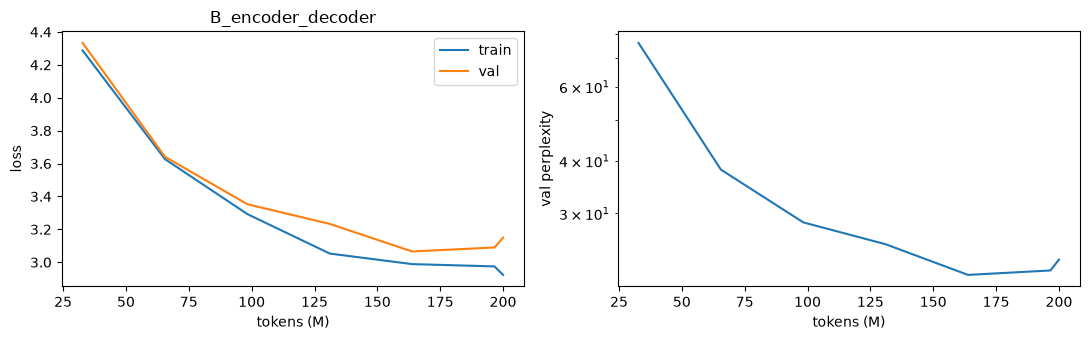

In [12]:
import matplotlib.pyplot as plt
h = json.load(open(RUN_DIR / "history.json", encoding="utf-8")) if (RUN_DIR / "history.json").exists() else []
if h:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([x["tokens"] / 1e6 for x in h], [x["train"] for x in h], label="train")
    ax[0].plot([x["tokens"] / 1e6 for x in h], [x["val"] for x in h], label="val")
    ax[0].set_xlabel("tokens (M)"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title(RUN_NAME)
    ax[1].plot([x["tokens"] / 1e6 for x in h], [x["val_ppl"] for x in h])
    ax[1].set_xlabel("tokens (M)"); ax[1].set_ylabel("val perplexity"); ax[1].set_yscale("log")
    plt.tight_layout(); plt.savefig(RUN_DIR / "curves.png", dpi=120); plt.show()

## 7. Generation

In [13]:
## -------- shared sampling utilities --------
BANNED_IDS = [tok.pad_id, tok.bos_id, tok.sep_id, tok.mask_id, tok.eot_id]   # force a full 128-word continuation

def sample_next(logits, context, g=CFG):
    """logits [B,V] (float32), context [B,T] ids used for the repetition penalty window."""
    logits = logits.float().clone()
    rp = g["repetition_penalty"]
    if rp != 1.0 and context is not None and context.numel():
        ctx = context[:, -g["rep_penalty_window"]:]
        sc = torch.gather(logits, 1, ctx)
        logits.scatter_(1, ctx, torch.where(sc > 0, sc / rp, sc * rp))
    logits[:, BANNED_IDS] = -float("inf")
    if g["temperature"] <= 0:
        return logits.argmax(-1, keepdim=True)
    logits = logits / g["temperature"]
    if g["top_k"]:
        v, _ = torch.topk(logits, min(g["top_k"], logits.size(-1)))
        logits[logits < v[:, [-1]]] = -float("inf")
    if g["top_p"] and g["top_p"] < 1.0:
        sl, si = torch.sort(logits, descending=True)
        cp = torch.softmax(sl, -1).cumsum(-1)
        remove = cp - torch.softmax(sl, -1) > g["top_p"]
        sl[remove] = -float("inf")
        logits = torch.full_like(logits, -float("inf")).scatter(1, si, sl)
    return torch.multinomial(torch.softmax(logits, -1), 1)

def words_done(gen_ids_batch, target):
    return all(len(tok.decode(g).split()) > target for g in gen_ids_batch)

def to_continuation(gen_ids, target=CFG["target_words"]):
    return " ".join(tok.decode(gen_ids).split()[:target])

def generate_texts(prompts, g=CFG, desc="gen"):
    """prompts: list[str] -> list[str] continuations (<=128 words). Batches prompts of similar token length."""
    enc = [tok.encode(p) for p in prompts]
    order = sorted(range(len(enc)), key=lambda i: len(enc[i]))
    outs = [None] * len(enc)
    model.eval()
    t0 = time.time()
    for bi in range(0, len(order), g["gen_batch_size"]):
        idxs = order[bi:bi + g["gen_batch_size"]]
        L = min(len(enc[i]) for i in idxs)                       # crop from the left -> no padding needed
        batch = torch.tensor([enc[i][-L:] for i in idxs], dtype=torch.long, device=DEVICE)
        with torch.no_grad(), amp_ctx():
            gen = arch_generate(batch, g)                          # [B, n_new] token ids
        for j, i in enumerate(idxs):
            outs[i] = to_continuation(gen[j].tolist(), g["target_words"])
        if (bi // g["gen_batch_size"]) % 10 == 0:
            print(f"[{desc}] {min(bi + len(idxs), len(order))}/{len(order)} ({time.time()-t0:.0f}s)")
    short = sum(len(o.split()) < g["target_words"] for o in outs)
    if short:
        print(f"[{desc}] warning: {short} outputs shorter than {g['target_words']} words (raise max_new_tokens)")
    return outs

In [14]:
def arch_generate(prompt, g):
    """Encode the (left-cropped) prompt once, then decode autoregressively from <|bos|>."""
    src = prompt[:, -model.src_len:]
    memory = model.encode(src)
    B = src.size(0)
    y = torch.full((B, 1), tok.bos_id, dtype=torch.long, device=src.device)
    gen = []
    for t in range(g["max_new_tokens"]):
        logits = model.decode(y[:, -model.tgt_len:], memory)
        nxt = sample_next(logits[:, -1, :], torch.cat([src, y[:, 1:]], 1))
        y = torch.cat([y, nxt], 1); gen.append(nxt)
        if (t + 1) % 16 == 0 and words_done(torch.cat(gen, 1).tolist(), g["target_words"]):
            break
    return torch.cat(gen, 1)

if CFG["max_new_tokens"] > CFG["model"]["tgt_len"]:
    print("note: max_new_tokens > tgt_len -> decoder context slides beyond trained length")

note: max_new_tokens > tgt_len -> decoder context slides beyond trained length


In [15]:
best = RUN_DIR / "ckpt_best.pt"
if best.exists():
    ck = torch.load(best, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"])
    print(f"loaded ckpt_best.pt (step {ck['state']['step']}, val {ck['state']['best_val']:.4f})")
model.eval()

# qualitative check on 2 held-out prompts
VAL_PROMPTS = json.load(open(DATA_PATH / "val_prompts.json", encoding="utf-8"))
for vp in VAL_PROMPTS[:2]:
    cont = generate_texts([vp["prompt"]], desc="sample")[0]
    print(f"--- [{vp['source']}] ...{vp['prompt'][-300:]}\n>>> {cont}\n")

loaded ckpt_best.pt (step 2500, val 3.0655)
[sample] 1/1 (1s)
--- [acts] ...ration of the said bye-laws or anything done or suffered thereunder; or (b) any right, privilage, obligation or liability acquired, accrued or incurred under the said bye-laws; or (c) any penalty, forfeiture or punishment incurred in respect of any offense committed against the said bye-laws; or (d)
>>> by the owner of such building or building as may be necessary and proper for the purpose of carrying out or making any alteration or change in or any omission in, or any alteration or alterations therein which the State Government may, by general or special order direct, by notification in the Official Gazette, direct that all or any of the provisions of this Act shall apply to all works in the cantonment; and this provision shall apply accordingly as if it were a notice in writing of the person taking possession of such building or part thereof; and it is hereby declared that, - (a) the Government may, after gi

In [16]:
## -------- local evaluation on held-out prompts (same JSON format as Codabench) --------
val_preds = generate_texts([v["prompt"] for v in VAL_PROMPTS], desc="val")
VAL_OUT = RUN_DIR / "local_val"
VAL_OUT.mkdir(exist_ok=True)
json.dump({str(i): {"text": t} for i, t in enumerate(val_preds)}, open(VAL_OUT / "prediction.json", "w", encoding="utf-8"), indent=1)
json.dump({str(i): {"text": v["reference"]} for i, v in enumerate(VAL_PROMPTS)}, open(VAL_OUT / "reference.json", "w", encoding="utf-8"), indent=1)
json.dump({str(i): {"text": v["prompt"], "source": v["source"]} for i, v in enumerate(VAL_PROMPTS)}, open(VAL_OUT / "prompts.json", "w", encoding="utf-8"), indent=1)
print("wrote", VAL_OUT, "-> run the official evaluation script on prediction.json vs reference.json")

if CFG["run_local_bertscore"]:
    # NOTE: downloads an evaluation model; used only for scoring, never for training.
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bert-score"], check=True)
    from bert_score import score as bscore
    P, R, F1 = bscore(val_preds, [v["reference"] for v in VAL_PROMPTS], lang="en", verbose=False)
    print("local BERTScore F1:", F1.mean().item())

[val] 16/300 (3s)
[val] 176/300 (24s)
[val] warning: 1 outputs shorter than 128 words (raise max_new_tokens)
wrote C:\kaggle\working\cs781\runs\B_encoder_decoder\local_val -> run the official evaluation script on prediction.json vs reference.json


## 8. Submission

In [17]:
## -------- official test predictions -> submission.zip (prediction.json at zip root) --------
test_files = [p for p in glob.glob(str(DATA_DIR / "**" / "*.json"), recursive=True) if "test" in Path(p).name.lower()]
assert test_files, f"no test json found under {DATA_DIR}"
TEST_FILE = test_files[0]
test = json.load(open(TEST_FILE, encoding="utf-8"))
ids = list(test.keys())
print(f"{TEST_FILE}: {len(ids)} prompts")

preds = generate_texts([test[i]["text"] for i in ids], desc="test")
prediction = {i: {"text": p} for i, p in zip(ids, preds)}
assert set(prediction) == set(test), "ID mismatch"

stamp = time.strftime("%Y%m%d_%H%M%S")
SUB_DIR = SUBMIT_ROOT / RUN_NAME / f"submission_{stamp}_{RUN_ID}"
SUB_DIR.mkdir(parents=True, exist_ok=True)
json.dump(prediction, open(SUB_DIR / "prediction.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
json.dump({"gen": {k: CFG[k] for k in ("temperature", "top_k", "top_p", "repetition_penalty", "max_new_tokens")},
           "run": RUN_ID, "ckpt": str(RUN_DIR / "ckpt_best.pt"), "tokenizer": TOK_NAME, "data": DATA_NAME}, open(SUB_DIR / "gen_config.json", "w", encoding="utf-8"), indent=1)
with zipfile.ZipFile(SUB_DIR / "submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(SUB_DIR / "prediction.json", arcname="prediction.json")
with zipfile.ZipFile(SUB_DIR / "submission.zip") as z:
    assert z.namelist() == ["prediction.json"]
print("submission ready:", SUB_DIR / "submission.zip")
print("word counts: min", min(len(p.split()) for p in preds), "max", max(len(p.split()) for p in preds))

C:\kaggle\working\cs781\hf_data\Phase_1_Pretraining\Test\test.json: 1000 prompts
[test] 16/1000 (2s)
[test] 176/1000 (25s)
[test] 336/1000 (45s)
[test] 496/1000 (68s)
[test] 656/1000 (88s)
[test] 816/1000 (111s)
[test] 976/1000 (141s)
[test] warning: 1 outputs shorter than 128 words (raise max_new_tokens)
submission ready: C:\Users\wreno\OneDrive\Desktop\LLMs\Assignments\Capstone Project\Phase1\submissions\B_encoder_decoder\submission_20261001_115123\submission.zip
word counts: min 90 max 128


In [18]:
## -------- export a lightweight final model (weights + config) for Phases 2-7 --------
torch.save({"model": model.state_dict(), "model_kw": MODEL_KW, "model_class": type(model).__name__,
            "tokenizer": TOK_NAME, "cfg": CFG}, RUN_DIR / "model_final.pt")
shutil.copy(TOK_PATH, RUN_DIR / TOK_NAME)      # keep the tokenizer next to the model
print("exported", RUN_DIR / "model_final.pt")

exported C:\kaggle\working\cs781\runs\B_encoder_decoder\model_final.pt


## Experiment log
Per run: config change, best val loss, tok/s, Codabench score.